# Lab 11 — Beyond the Search Box: Query Autocomplete & Audio Fingerprinting


## 0. Setup

Packages used: `pygtrie` (trie), `nltk` (stop words), `librosa` (audio; it uses **ffmpeg** to decode mp3, e.g. `conda install -c conda-forge ffmpeg`), plus `numpy`, `scipy` and `matplotlib`. The cell below installs any that are missing.

In [2]:
!uv tree -d 1

Resolved 224 packages in 23ms
ir v0.1.0
├── altair v6.2.2
├── annoy v1.17.3
├── beautifulsoup4 v4.15.0
├── bs4 v0.0.2
├── feedparser v6.0.14
├── ipykernel v7.3.0
├── matplotlib v3.10.9
├── nltk v3.10.3
├── nmslib v2.1.2
├── pandas v2.3.3
├── requests v2.34.2
├── scikit-learn v1.7.2
├── selenium v4.48.0
├── sentence-transformers v6.2.0
└── statsmodels v0.15.0


In [3]:
!uv add pygtrie

Resolved 226 packages in 5.97s                                       
Prepared 1 package in 84ms                                                            ⠙ Preparing packages... (0/1)                                                   
Uninstalled 1 package in 68ms
░░░░░░░░░░░░░░░░░░░░ [0/2] Installing wheels...                                 warning: Failed to hardlink files; falling back to full copy. This may lead to degraded performance.
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 2 packages in 264ms//mnt/d/workspace/inno/ir)     
 ~ ir==0.1.0 (from file:///mnt/d/workspace/inno/ir)
 + pygtrie==2.5.0


In [4]:
!uv add librosa

Resolved 240 packages in 3.75s                                       
Prepared 5 packages in 7.75s                                                 llvmlite             ------------------------------ 56.20 MiB/56.93 MiB         llvmlite             ------------------------------ 3.23 MiB/56.93 MiB          llvmlite             ------------------------------ 509.49 KiB/56.93 MiB        
Uninstalled 1 package in 65ms
░░░░░░░░░░░░░░░░░░░░ [0/12] Installing wheels...                                warning: Failed to hardlink files; falling back to full copy. This may lead to degraded performance.
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 12 packages in 31.23s                             
 + audioread==3.1.0
 + cffi==2.1.1
 ~ ir==0.1.0 (from file:///mnt/d/workspace/inno/ir)
 + lazy-loader==0.6
 + libro

In [5]:
import os, re, zlib, base64
from collections import defaultdict, Counter

import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as ndimage
from scipy.ndimage import maximum_filter   # scipy.ndimage.filters is deprecated
from scipy.stats import kurtosis
from scipy.io import wavfile

import pygtrie
import librosa
import librosa.display

np.random.seed(0)
plt.rcParams["figure.dpi"] = 100

---
# Part 1 — Query autocomplete (Suggest)

## 1.1 Data

We prepared a dataset of 500 research-paper titles. Many share prefixes, which makes them a good sandbox for testing suggest. The cell below decodes the base64-encoded, zlib-compressed dataset.

In [6]:
compressed = "eJy1fVlzI9ex5jt/RYXihiXH7fLtbsmyhIkYDwiQTVrcTLCbVzMxD0XUAVBmoQquBST06ye/zDxbAWhdX8Y8WO5unJN1lty38/002ZRZlTXJJuvmq8S8dk0274q6ShZNvU7azjSmTvq2qJbJpqmfsqeiLNqumCeNWWJYsmzqF/r15Ptp0pqiXdNPedZlSW6quuB5Mrt7qdO8WJuqpWlZmbSbrGlNMq9z/NrOV2ZtAAQLeMY/1YvkJaPvJ6vst6zJ2+Sl6FbJpi6zpvjN5HZt82xtmqylqek4vTFdO0oIytSYDf2noi9MTTtvik1XN8mC/velLvu16Rpa52yVbYzCTcb51jQtwaa1EZiXunkWoG1LG6bvXa6zpUnOTdb1jUlmu6pbGfqJgd7UW1MmXwrz0mLdWZXcPv3DzDsAmJ49ELxRkiUz2lZJUzsA+lLkpk5Ps5ZAfzGrYl5iqR1NqhtMuzbtau8QCXCxpnvY0iRabmdekyeGkFVFW3dNvcHxF4tFj1MGmLv7m5tR8slUdEgdQPCmk7umWBddsbXbvzfzvmlM1dHe+2ZwBPcfbz6OknHyuSoWBX1svKElZIQu2LpuKqvy5LovuyLd0ingCuQEEoCuq7ZresYrwJvNpqPkymRNhQVdFLS0Zk4nQJ/V420F/e4/naZTOXg55/G6zmkUQbfg5cgE8H98nNLXlnRd2CshJ13FdbbZ4CuTjK4L2BRCa5rVrlutiyxJLiv6cUsHINgpt55Vc+Dk5OYmnf79JuWjHAtu3ZuiIhhzwlo6NLeZ84bQEQcnZ2PWWQViSe4I2RWpr7JmadKWdmuwkbu6IACTsu5zHPakpoW8dowxv6R58tAYk3zqCVny+KTcJwlkCCNJPvOXrmqMUnA9/tgbfOA8mxuGfm+yMu2IIpVO8MPgspItHY3F9N8ANblb1V2dNjRX2ADPkjMl4LfnyZ3JDQEoCFUfmuwfjM87wjeTFwKTF0674Ru+qqtl+mCadTLuu7qq13VPO7iuic3QYuqnGje8KesdH/OUGAt95fPN9Oz+8fb+ilDpakZXQuS2MVU6q3u6EKIvLJ+wKE+viuWqS2bzrOKjmu2Iktd8Ncl9tilyIowazGCXjOf/7InSBJOuJoSfmPpiGACQ+2yxAKJtDba1WNDWJzWRomlb5pYEcgrEK556MAvCO7qnyrhrOvkhndbnmCvcDRNkf+cYdk0EvOlLQduHrCXC+2GaTIig6TCqgs6QJo2S2QYj6MDWmxpUOrguRuolsTYiRNo/QAhNZl2ZtYR5T8Slzpk3KEPB+RddTzyYoOk1/jA9H58C0RlTcXp0FwSKrhrM8ezV7Rr3Af7DHz4tauWrYBAlISnWRODyhA52M0rwhzV+KLqk7ZsFMKcA2RG+EF8HCueOmv/8/v2/Jw+EnS19F6w+eVgRSjHtOdT/bkx03eLG+3yHhZV8TnZGcm26VZ0LsT8QGSTXheBBR7dwSwx0UdYvfzz5ka9GGcpdjf0ANx31/mJ2vLz25MdpNOyMSGAtd8ZclFCV/ivHiAOcmWxd0lnFHFPuneAyz1FxCxQb90ugOaEPaLPodvje8ENOEFxaQSC7VEFAI4Qb3GVF49jpyY9YFz5XZcrhZjvCobbo15gy7jphfXQhhNfLimWD0kubfHz/4fuTn9IvhAgE+bz/7bcdYc6StoD9XDYkBYGJPE33otiwOxl1pjSbVV2Z0WhDErauRqM2K8qnOutGo5cVwRyN6me63Hz0PxIC980kK8uE2NJlu1pnpvwmSZOL+iVJ8jrZ1T0UhKolSjGJWdf/KP56Mk7+bfNvaUb8hYi6mmWTJCuXhAjE2Xl9qihsiwDvL8DyyqQsFhCKBOLbT8XTU0sKxAuxoW8JW+arqvhnL6h9Vq0gCkgHqBYEi/7IogWktYXGQGu5q8tdxnyeBAB9sOVTeGCBfF3npmzpI8TuJzXUnpR4KNN9LC/AA3HNc4JTzYnJtoRCjBN8awJhKPj4Q0MsuSs2psQHRBiEglSghHAtBjFPMh3zgttNV4gAWemOH4g5L5tss9qpDpUIP2Zwi74sd6TMVVv6STGsEk2iEk2Cl5kldHk50dZLVj4ThXY1KY28kCQhIZOYtt6ssiXJAODhA8EmvsOcmI7LlDl/sTXCkUkskwgnNouDEKWBNnANnbFQ3qgYSXD+/NOfflw/itADWyGJhN2s19kTcbfoTAkIU7OwTmF/+hcdN+s3xH87Pdypoe8KHLr+rpX7Bll9+Pnj+9cP7396L9peknXJ9+8XG1zBT8lTQUPdPY3pxOolDmRaEEcW0c0qXgMNtlgKd7+gsyApYCBiJqz5hsyW4J4SZ7MqtGqX44gaILV61gQvdkSPHekX6ZSOirmBcGyB8sJKN3Rawc22JU6Gq+LfWe/4UrTQLB5rjIy1wt36qS5bXYEi/acmKyD5x9W84Cuf1LhmEk0tKZbBFpZpvUgF6hmJ5a3wnWM6qixPaGFw6/g8zmkji6KrxMbHl/oTnzyLbiEm+u26aOe6IFar8+S277AcJ93xmbNXgkmcPQGeDjVmwIYxdUwppFUIsjA3pCXBmiHO9SyciCe/S24Xi5SYSjHfvcPm6iad0CUSa4ivE3S6Ft0MBDQmlIF1QeeA+7PgXgo6B1IkSHcDrkUQpqKXZaQEOWUF03aEdSRmomu9rfjI7JUZsMbWrGk3B6cQNk9YP8kgkRQXsr6FrmE56bGJdN5zEm8szx+anuiRhTLBW5SF3JXoe0L2zBlYxC0bj0gH4AZMkjCYSCkDI7oBBdNNKPd0XPwYFHe37ld7/cI7RPt2mugxMHLBe8KT9JMOujgULcekv347BOyBiJbx+4JuXuncSnvidnRJ62P7Aa4wCW29xqrcoiRkrXGk9NN5UXZ8IyGY07puhXTA9sJfJiWB4l9ImsJCdRzoiWQMdFpYWqK7Rivju1RtSDYfYaFbIWuDTrq66RYnefDnqu2Jz5H0Z85D8pUElbcag2kDMhX/RHwJys9I4F30pByK2A1QKgTH7HXTFGBO4er/xuqZeBOmzr7HtYuGBg8HYL0TTJKLshwe93wxvefpg3uQyY3pHHKDIUAisW9hRne8tuwic6h2SUKIFFyyyKDZd+KeCcGSPG2KVyj/uDCdKRJO9IXS4phqA36m1yqU6Hma3a0l8B1dUW5gLJf7dxLCcJZOSHanBNAsPPUxk3CGSXsE1t/UYO5bwWcWZiz6C90IL9EKmCNbq0li70RBVAwgSJ+JpzUdGN4OUEm0st7JGk0yyxam2yknZyWcFewINB8t0ci6IKXcRBR+Xjdmngm1fSrrJ0CAPwzWbF7sYaC/JSZt+qYRRX1NhJV7HDiD38MzqyTGElFyvsA4rkmttRbs4Q9FXJusphJWApuWgUV4cKZ1UYmBXYkukopRQ3YVLZikxc46Ug7DuCvpryEzpTO/f5glnzLYkRnIiKDRQRKDbSZkxneH4cw8xwhwhMkRNDUtyMpdlaSGEludw76DP61u9oFZKwFID00pYkbOvryviT4vq7zfR38LpaI/iLGs9iLtrAoVDjsBXyOGpVo4oNqzo3OFoa2kRDjUw9fyBfYL8coIisX7QM53K1JehXPjKOG1IL2b1KVXRhlZqKj4yU2GW2Ro+0LBwvanfak+AJzxJcjBdAdXM5vXKk3Yy/CAFV22qlbcVkoR5Y79lCTPA2tM7ucgVFZwIWHmdBydtdaU0TszsLUOGxqTsAI+X+3pmgPIWaQG9cQQ0iuzZeJuquRXtmcCv5gYpsmK9EzaJ4gmt3zIvEJTT56r+qU0+TJSJ27qaiPbxKFEkibgSoQHxADyXrVNuBWzDuI1vTftpob/b9I32wEaHAZN2xHpxWSSemw7Pjdk456gLp2G8k7kX8jfiio2sNlom9HEeI3CqlrVEiLFFqR600OIz+Yrk/cseVQRCkFAD9+ob4+ACCMqQyE562pSYBg7yIbJ2XhBWMEaQwro3ixUhAHOTFxc0Wrve9VKxnm24Q+CFJu69N4bpx97f3QEYgbLg62YUKll11fmeN5B53QI5YEEPS3jkFSHz5e5gop17/Ng3auonpMAbUOgPIs+CL16RZKu+bZlQcZGDgufcxjo+EopopIgknJlSDKyDIo2GjtxcmehkSVNp0LSdQ3LxoijZdFkfY6tF4yZTDp7CkBWqgOMzp0Obd2zX5yPSi0Cizar0NOezCM9wTLUzvoytodYKMdDBj7giCOYkDgXZc8nLDeQbLwXiRnkdXp/GwEP4HSkZqbAX5jQ8MDAK0eqw+DCCTxZSxz6yJt6U/cR5hpvFIWwM7q43W+GpE+VfiK85LE42nTpA0qIC0II2lASXHN0OGxFx2eydiy/Ec7JZis8fy8NlJ0KV7oy7AGjczfO0RxBwWIC1rL2rCW4p1WxXEXhRlgcpGry6kNodaQQB3tfFFAAs3aVmH/2JMCf6JJPJpGDa2D4y/bHimQGgmhDn2MlAjLk67NH3myxavI7jg2kD33lLITDCgRbm3YTKlKbrN5YhWpydWadfwfXcLej4yzkEIW1q2IDJIpn3DaFuKhPSaLlGbPj3x0xItuKCEWlRuh5hDmDqxLBqJGPGB67s1M4/WJbDA72eORpU5BwJJOgewFPIU2EI1t0EeOqqrvMR3Fxlt9PJXg1LotlxX6tGBpU6hp3YcMyoWLpnD2DOcfCqBohgZXdA6w3QP8VANNdlSHAfn2v+xgGV/8VYNekcMyH3rd/BcCMTOkyPa/rjqxcGvOL2dGPOdSjWvjPENoyDJep89DZE/HgGVEds0Ro6/bPTpINxoqpPpFUAqZCBHdKDf1+aup+wx6e4XVFE0cWYXfJBeEHS6h7g6gB4c3hiTFCKgNwGsKdoaHdPoHMNsUz6zPiwrDShIwXaBiQbKIM2FQDJz4g3zAZfx46HeNPPLA8chxllMyjawYgwqOmboE++XD20HEf+Nj55pbGRvpYBO9fSAxAjbgmvv6cY2Ubr//CPs7V972C4cixhq9CFjxsQ4YCyq7FS++CiZDayYodNi1Uot+BibUQ1i97WNYk4MmWb0krICxarkREvEJYEvXZUBRfPm+BlB7aUcJr//qxtth7px5xmltysJWDok3AaFhgwSLirZp1zf86uE52emwRYvidT7IV1xmIOLn/eY0MmFX9Ajpj3el3IIiIr19S2vpzoqekosdPJZkjfM6G5A0kdmDmqCV1ORmL0VixcUtq4ZIDA4bAbDnnyDTr3l4tGZ/LHvThDI5JXT+rsQC17bmARliNLKv+zcpNlTnsHGU8CBwiwDsOz+C+VGZaNqIaXPALreNJ5QvJyIo4Bn+AVH9Vku+98S3ux4bTIeacFYAg9GFgD/UmndYvGjwl/lmv088bMnINqchrfAvpSX4qnTC8GjJgx6u1FlM65kO0wVsJx8ifA0soAhVlluy5NyDA2dazIaJk2/4JKQ6vTnWKoF0icMXs8aAZEg51vI2PW0XCuNM8ini/4ebg6amYaY9haG3N7ujQI5k6bMwQHovm8Vg0hiP1bLCQwjXf3xacRuro3gqwachhJrs5cmJadZjFZLQnQMVVwr5zk0tCAma5cEr44YcgJc595dQajCSGGyxlW8zVGIJB0WStCz4MYBU2bYjd5+MlseVlFmk14uzgmPGhuNpxeC7TDstQjx7S47yUIgUBvn9j7WcNcy59nodzs7HFgaSebvVCrEGMZ84CQbQs5wyN0mlRe4DD5I/Zbq0S66auKt4usERc27EVfAiUqBQS+2LL3bnYg8HnjagpIvDdP2vOkVuq6F50Zut+nZw1DU6a/Rv2INlPjC+0YgZZK/LBC5sAfj60/ek8rdJ2nP7cZN2Uo4pHNmGC9J0o2PW5RVYNGf/K7MKNEo+4ixJEQ2cOctRYU5qL7j3eZkXJQ7udh8GxUg4xya0pQjCa7us7wSS622xFA+TDGcheJVXLUQ8vW+YmmAmPkRgGEtPV6IeVJqS/VZJ/d0qyLp6Hg6ZNL9VTN/Hhc2agPlTMqqyYaW0MAn4Wq/4QMmaacdhpDCNLlsTf044FALaFvEqCsDElR096iaTQ0vKCZcrGsVGNlGQlC7dTMmnzdFJrZNgZjcHWoR+Nc58AQMAkK5gUXFJC2+RpR5yJqHQnmOtJRW1/uqwUCa60/jwrEWOejR9w5e53jCVVQU6qAj4i42FHe7a/XBevJk+vif3R/a+KTeh1Oy3r+fM69Bg3WTrrn5as2sOh2mgcKgQXeKYlyG+jCGRNGmao3hlpp20Dz1fhYtTyoyqyGi0LghLXJms5zYrG7dJ1jVBpTTytCSKNgYcvkgwKTRGbICC52Pr44pDkHZ1QuW+xSSY2EjIJ/lU9r1VJPCPGWrJ+l5KU/Dt8v50wPus65MmwrCfDpE9hsOwrVi7JItVnmuhMm2Ji3ZmBNce/t4OTDwk4GPALMSFJfEKkTd0FqvswC/J5OzZkFs1/gONx2TvuiCMlwrs7HyXuLxbvbSquO1uMR5gbngrcD2h/UbxKRiISY0gVYn9DizRDm2lBtApfTWuJGzRCjCirWht6pYuii/MA8B2kbTJdWHVY3csbtpyviAO4QJjN52yIT2pOPYuGeh6kqFuYEFZF2/SbLmBgM6TZaK7aMB0V8/o2ZAKMYTBrm+Rsm5W9O0uMcwKJWQrnUsZ4iI+oMOFgqc7LlMiZMZEkTyQgzvEw4dYuqEFY2oferbWIQwDerBr4cvmw2v5J/pqECg5/TCjsrIL6yiKPpn4iAyKjw0q+mOZJ7rzV8em0IZStkl/cCoIkYB/N5AhCwKx4qnwqzMGWBK5CV+ljewFf4pkl65vs2Fuq9Xcm/uyH3cbfzO+O82qmTfC+9I7sE+aIbHP80hRLLiBgXyS2tSY6EUP+CeY7MUPoLV3hIk50reuijABJCj3nm81W2bMBtl8iRZEtb+cQGTvreDCXFR3GHZvedmVei7kY+XxMrSbzyLayMC0pzo6+AqWLoerAi76/qOeEBZrgz6nryDc2KpaanJXkwEkqLjTJhw6h3RASIN/Th0HUan2ES7sh/sP70PoAOxEsHonu9T/kb6Mgu0PXJP4hH+gOa04izth4s+IbTuunAyKxAh/njhfs9qwGti+/cLnh+tFvBvD8TWSQjZxnnCgBfQZSSxLlns6ZYHdyOfprWlr0F1V78KEb2vuOCIHwE6qiTVzmNDQbD5fvnlj5bXKvH7SO5pI0TaGdceibnXIlx1voCtS/L0Z8FC60TMjCPXNOfOGqgRvncLAL1vT9ebQ2/gDpk/Bts9plo4mjIKnKRq1a9QuQddUlEf+w4MgUSe98IONK4ibW66dpTcF4DTctXIkMKppIP4IMKtKAc5YBk7eTkUEaqjS4zQV0WyN6nfFWRDAtvZuModcXZNZsrJ7Lt/Otv56XlamCnJkauYYZ0kg8HAeS0/Yy1sY7IxUrCaumQhuz552yGb9zVtOtfkE6X7vJ5oMoAu0FigeJNyLQOp5pvfsYdF+ALVeawdNo/vqUXXyBYXfCWNCon6ruOCzBLgfVzcWH9GCyNcFBwvSS0/0DyvapTi5Mq3mBy2KuSpPkjPhv+XBOtoOolHzfwDEDsYvMcY2j2Aq0EMQqK+GcY7qlfzxIyLCjdSPswuc0ibJE/EW1iRAiGDuxiJErd+HAUxUUpbmAORcueGfXaV12v+G8vRstgIsaLcPyUiqlhE0kt00uETzrzcqJqa8lBPECB1a/XnuH42F4XFiE+jZe0Jws/qxohaNzcNzWPekcEjCcIBRAe8heC9Z5eiuQPt3NfD1TEQ8GHhAsUy27VSjAWpKPyJEhNbDeWp8F57EHs9mmDkxqFSKBIX2lOVS08LYWdQMEM9AEwxVlpDsj1sTlQmyQKqOUs/k4JbxquyA5i0ODwXwkhb2aueSJa6Z8G0Zt3FqCWXPJXHBqGUoe/9kTSvdkzeZb+gOkdjC+ZJZrrDHEenO/hnSS4tOCKwurfl4asmhy0vi0OiKxPuFw0XD3N1Aa+dB0Md4s9AOXhvMNUaeZPLwg8NwQJvN/eFmmNE+N+oZBhaCoaH6DOFHS+aTktRRZiS5NhyRWvqhTOIVB6awNMwcwvRasxr+EA6x1Yf3vwQz2AvS2VmktFXNcZ5Nk4tzeBaPh3cQNOOkxknl/P3/gPOTJOBgM24EMbqfXZ7RRdysvnJYvFkbRJB17tP3cvsJWiCUXDr0WfeXUo8InaLN2fptkzgIh6saekFoQxP4lYk8foJt9GF8n2+/BamPDWEoqZ7akclAVp4y3hqOgrGGoK7gOUQpsLazT8XY6OyTAGtZZemN9hqdFRXYx1Ct1jntYF0VONm6YEasy3I0YiHjnE8SOBjQvIz9BPVZxYUsEvPXu4MpKA9fJoaTdaHjgGmHrkDnUZIVQlx8XugxIle5tpOuJPR5i6Ab5/baiRrmCwJitikWXFtVWc4M4GGt1qbSDYI1c8i7NxAcfAmBiZfgCT92hV6/c0Id+/sy+w6CyZTTISovTLLWOgBf2ku00CX0PcKgtol4LiTVgJ1rvSxq5V8SctW1npxe4Dq7RQ+J/6mLFQQq5Gxumr5AMSKfK4HCMecFOcxYYl5eEP+VmlaWnhpYc/uaAcaBhlDyREpyLdNXtGA04qHGytAvKNb1NAYBy2ZXRi9vDMTThMta33Yqzm1lrqXYa2ZP0N3GDvIaMTHOezi17YH1Z4oJBJpn6xyZZhdQmsRmcdhfdzwBeG1ky9iqGOKAHX6vLGTY2quhN+46kpj9jsa+GZnb42TAaJmdpXbN+TF5kXpKCy0bZR3xqW20F0HKNFx3zgvh6AIIGkY5l/YOctzrvSfflZPPL9VNWSqXiwEsYASBu55izK7hHJEnUhXKXBhR25nyVsMQD80aTUdoYNnYl+eQc1agr0YOQ7KAKOWMNu9oW7FiH04qWH6bCer4ZA3YGpyZ9qZ+L6I2vREcu6OTo71zTsh+/hrGCSVZIcnY1DWIrskWOGpd++Y+n00JdKYi0ZFXmkYsjE8OMKq+N6XxNUXWJWoTdpc0oFpMyCmlacxdaCm3gC7H06AZbV0CjSKOOAMnoVE9DPayrc3hiAbFieIO0cu+iLipN1Ce9Z6BdJqHTgdm2Z9XW4+5urf40vrwaBRUpYBmX60LNNc/woVCoRjk1axEljrAIys0QyKAmykFid5TP41RiZP/hEX8LWoXwV76Mz0bHJh9h9jJxnb0mbWzG2IRCJBwKJboAf2BgS5CW/6HwFidXoHH4zmw61rBCs0l+vVsRs4ttgUhMuj2EUd0CsS0x27Hxc6Lacscy3x6Bm2V7nRyoCRR3w/X9pU1L94zXzUfeQknHPX/WSCSnNnNS37DNyCCPKaIbBy/ssAClQ0IQQcreO+lJMg986QbmMmQOMVP8uJNDYg9GaWRdtgKWq4hdWDv8MhIHwRxYdqmSweaP8wgq7zkjnSvP1Qesut+Wff/98E4cH3HhHc71ECkh53MBEV+T5M0l7sXOlN8BwopHECoL4bH+SDze5E/Z/HkASPyXztBGPWs8QvKEg1Ytt4rbw7y3B02OEpdfWHoYAXSihBPZ9q1XP3DQhohDmIglsxPg2FCJfa4y/N006kA/lHdxDr+X9U+qtjZcK6LX7YA8PiE72TonHEQ4mrV0MgjFRxODslTFubA2k+37aLxzHjFPcWmfA+YnjYbO1qKk0LnPiq7f/7iTKwvbBWOqFpUfUnfKHMDk0rOQy7kx+HSzlZjDMIY7Em3ZO781gF+ib8Nk19kmK4eYhk81Bo2TdoYgUtYQr0OQx2oZOHKWniW81VUlRIAWPtluD94/gs4Ioac3LmUIlBw1LIJqqAhi37R90cFKO1Ys6kMosznsV1umFoKBWcr1jozT6M8hZdkSPF5z/UM8njRUs2WvLaOQTY/TEOgIJTvCTOmbtPI6+UNy2ba9GcKxdBf984PLLHCeXOTw3NykF9fXg3Ko4Vb83Emd2syVIyP261JZbSoD2+jArDgxzJoxKN0tQK3QBcQyaI8BgAOwtTUrjFBewfTMMVR1nbPz6yBDvSNgvNNiwdjFWIB4Q6DJ7MPy1ZbxTlHfXnC53uGJTABjbgf1lcQ2kkqkxzKBLPfwyjmHwYWRH2Nr1k22R/WfUbuo9sk9/g+TLlyqTVQo6m2DCMQcEUqx5ea1Ca0JJLiwH6udoxHbwVlQ2PqWvU6EMvCwcukjjBY6ZmtjgjQbs6Gj6eqE5B2RRZMWKRmN81UtxhtyXds6gcfjjozcGgoQKQHJ/8ma/yy2ow8f3//8pw9/+fOH//svLEMjMp0EbsN50oCN86y9xuwU5s1BnW2ZMUgc8txF0kba54eTYQcIvEauSOJMvlxLjRP09CADsiwGF9+EDGVRl89dVrrA3PBI7SKHO/MJSZKPQ+CK3AdVfQ1OPMumMIYlNlHiNqEHnVRDai2cq5yK3LBxhoW0KN4IAb6DSreF2av9EsQXkRRBrGjPgeMnM1rT8D9Izj/33xBpDOpniWSg1Llcjp/2+ic9Qviv6g3YASJ52l0D3mmnnL9Lbq7vv/34/v37QzCnNdRK0fnJdOvQi0l7+XRcDy+Kr47+M5oUfqWFk0R1vsP/XV+hY9OH/3X5t8n48o+HPn2GljpklSjDsT2Nqqh6HWdJqyL1mjnaZZBEl3xHm/p4HPR/G+yHn38+Ahbq3BvWS4D/fBDwebF420kQ5J+PQn4D1J+OQW3a7g1Qj50CoB7H8HGz7D2tItou/b8Cn69Gf0NK8FbqdwQgvbojcgBq/vjfWkPc+41taK5hOgir7ps3X+tPh5cJ0G+518Ngr8zrzKz/nY+19fvGaR0afkM6zZsp+PuDKyHQbzq2w1DvMqlQPZxtFez3/Q+Hps+4UukNp34Y5xQsospguaQt1OUevo8GBhvj3pVPYQsKyIkDz2bjb49g+Ix52Ftv7cNXYL/l3o7ALV7fvOL3RyG/Zb2HoT688RR+OAyV4+n/fez7y1Gob+ZSR0C/mPJN4ufnwyhMcMnCMW9ChyNHDMi79G36A7HLw/qDQn+T9KSlH5aeFvibJANBPywZFPrbOCBB/8qFAvp/gX2E8PfO/TD7sODfQusE/AitC/A3EScdzGEKClWP04YzxKyfRCymyS27oSSK5P2BaXI6ntzeHJXcUnObfFNEig4Z5Vvx+YXfDVvEti6UoN6qtUStuc8o+tRwO6pvku+Kh8fL2cO3Hw6TWceH9f//6xbb2jbo9CUHp62OUIFFWowUi0WBejfzOnuuMi5fcMlxj8VzoX0UEahmnQKLXnCWjpvomiZzzutr14hB7vq3ISLAMQC4b6+ylqW/OEoPAqlcFTqfpFZ1cata7u2j7cPcCt55D887dUDkXCor+Og1Y7bkA2y1ANLa9lG47KKyxigAIkFEuAWy0nWjki7HFhBHWdS4t7nTyfgJGYa31bLmjBJtwRfMCOmH+8RVNr8KRjc7JL11b8tL234u7bDWUnofA5TEoEebP3RxN/sUDkBgGg2qOHdl7rKle/3ZJxdjEhDI+/pt/x9pZNj6zpqt6m/OavClpYm4YT9XrXcAsseAq020RxpK0FbqVMYnW//tvYL6sxSlowbZ2ILmR8vALAyX+XBjNFPRVn1z8vogq9f3aLa1HxaOODIlbwndNAiXOY0yLA6YcUq/prVJDZV5zdCfn8uoECa6tsX8Fq6mXkRdCeMWps6j5aOQdjJy9hd1mWtFH+ddpPfFssj1CQK+UPSekuZk2LJ+0EXfgl6dtiZPoc+QBOy+dc+hiboIutuOElQLpdIwKtTfg96+Ws2EdN0byQBwEJu4iRxachHnXpkSKj4HBdv+KZVzK9p6XTebFfpbbrS9lML5j9NG+nfF8SzwsDsi2syO80Skfhz6BP3EhQYTyZyxia0IZ0thCdc7ofjbB9E8OK1r1p7td0GGxCTbsN/ZNi/eS2HYq7W0yA8S1SQ3zRiTkP+IWFTykD3TEm/+5wdpRUqcJZr3yJ30uUAt8Bsw7IUUEJ7XzbyQiu4b8zLo5eWqY8OWJH55EO0cA8NhEZa34je7Gk+5fpMzi87u+M++p53QwQROVTxTUbTPrmZVYJbKlm4n998yabnObFzHH3QHiYZnrnPGk1kVtrsBvx6Ajns5UTMiW8SAnxqTPcvkLtFqJNswkitPdYmrvqnCnlt6er5nICe3qzA3YQVZwPrQSKUut3IakstSsNPePNHhshDNfZ/Yu7A9tgYRQmfPXYa8Wam8ANuE+HWlgpq3EFSBa9u5Qw1lYrgEjlOTXMGY/G0T5BaGw6VFahh7wXrpGq2/FoEn09g5TFinZTZ/Tk/r1yihJxqCbu4bs0HSsf4AseZyB0wTPAvjlJmwV4NGM6VSILUtkSpAEW2Hs+uMBrbMX6OPEOf0HYoR4r0ep3NJpii5fyUJcRN000oyDdalW8mlaaU/YesqBCx0F4ATZUvqRbMylcctbLE/b6QIds6Jr7bNL2MkiMinm0UDz641J5cDJ0xz115XjAsaOO3W90IKwXySd4U4S3h8ozLLPnkgmam7d97zrx0EXX5GBCuKjQmf5TxybaxuH2U5xPgcDP0tbDivySbRsCNBOXkeAu6iMpCjmrn1XPC90jFp1gtf9QBsFPoPmhAAziOxkXIXti21j++EncEigD7+yFJFPh2NwM2lJVoVoTNkoVF5P+9QlnUYU7fpypHHVhJSHG+PPuhr2Ii5rJKLutQWCCXKhpnYDrWhAitauXzGq54raYLAkrQNf7BVDuEXNaqnlRnD7AWXfbT1QpOTLAHnXSLvEixQzmFRm1WvaZC2q7ltMy6+ir7NkWy802TyeDvO0NnvlnaiKzS56xLcsxET/CApyMf7VdpWnKIFEe9JpVn9jB/gSpKeayOAULjLWipMt+YV6hjxvH69GaxE1Ef5Rthyw4fIxV60qmJ74s+Z8z+12vti2LHPKuOwbvp1qlHXU+3jN6mVNXtQOEpRMwbt3F2q5gH6ttM5JwgomyLtifZuNtHv+swWylgQa9USe8+D5/0T98OSlmP4l+9/fJ/mKP+jU5XeTAE4IvGaFdo5zeDyPFbyDg4Jcq3tOH7zyCxE7emCVpkqD3UcptaLd7bFUha8FOE/lPLWtXY7CuhLSd4+LumNBZgB3aJ/WjsTNwS/CMC7hHj/O79F5ZDlzO3ptkqlp429OqURUVtt2mBAsw7mVjpoBbyp4G6iqudospeQpn85gXOVIBtdzbeepWZk0oK4Ymq3N/OqbvG2kqYxcOlroNzIaCRtwGYHikLPcmmDoWADwP9tmjptV3XQr8VB+NRosHoIgvXbYg7uoxznPCwSDcAzf5VH1HSRh9rLuC+ibfCc60dn+LTfTTp+QYmnNY8PNBVX2Tosedaia80VBri61So1loOxrObySwwjleupCGyCUKvEwCp9wNmfkpgQ6aGi2c7sgu46d/eXs2v65bfH4jfgNJyqqJskBoNEkqp9kSQ/Pcq/9+iOWtvaz9MSKv2dqYm+Tr5UaENxc3UHq+VLYboKhYRm398S+Dke6rp8LrqTLySan0Avu7i+fcENk47fjZ/mewoNqin/S9NTaXzLee0d8s8kLz3AuxrUJ/2ZWHMU0rN+MFSi7nVm1JIgeB0STWRAv4c7x8KgVu4B5oO90b6uXIlqW2Vo8/kgDVtSFDUR+wioz/D9MLFZOP0eHJfOjR+iyv7jCeMiNeSbIhBaUy6SlSk3qlaOpJ7zDA27pfnGl9an3vNMVKKNEgFyLo16JYnFvSgJV0iGl/Yqr9bQJJpeooTS9q2QuuX0ET5IVR1lUezMSAkeEmHmrjUYswKbS0rsNebI+qbTJCvnFhNxlw9J2bMSJ3X2rjjuIis7JMLVLyS0Uei6ySQH1XpJFaC6pYLa5idxNItwkVtyuciuduckeKbztMjYLJoN+zzGGugIwdwGHWHYEpipQyMCxTpF2DAr7PLnziKV/DrL533OAx0sdCLbWCWEbN+Z5JYjFSmVYOSqhsuNXsNk0ixaS4tu+kCZHvunCu7gUdyIDw8P9an/mTif7FM0nhAWKVwVYXA7YtvRCdRw26QsFbGaFgHgvu5BI0NbZMJR7kZ1s3CGV925nf7kRg02NUOGrWIqfqJVYKCJYqFYAqsUPklp4p27dnJojuz2cc/tjvAkk304IAky26SP4NV4ymvKSXVwbSr0IwFY+nxHGGotW1cLx//+PfSOETch239zraiGb3cqq/Lr3CsMinVPfML1krqP+2jSb1YCkqluJJ3tlvCLef0mWwc285f69fpKxE+Iri6F3LVLoYF0paxusUZFfzclZyDTP/PTALEhElIgh79iW4Snpzzf+fZcX2J9MI9tYPdgoatpusH4p7pZ1TWa/rN/WODx6s6qPOUs9DxWBoLT9nGcvWdg/bYql0oetJ7tSPo+1a+iNIBPFtoQ2iayD1/b4Xd2GJl4OGn0XjxYV97a5kh/IT0LzP1gRxHtfHo9w6CTL31J13BnUKbqXpV1HEj2F7xXSsPxWTUDgu1G/26Tqz1VH/z5iJPCP0jlHYvjDq0p25PHlO9mHLy5JCn+vby4EQQqDhiujx+/XE3HKFNdE60Nupj7TY6ZwejloiVEsY46xT2OL+5nlzN+m5QEz5xgvRPDMXjy5HGF51TQSYQX0khPwxvaZMp9MRt5O2/j9ZHH8Ww2Tj++//AXhCbwOzf8qFFcIXIVnIZDEjz2891fk6vbq2QURKDYGtCn4gIVzUW7tNEAzf/1apyk4YvM9kViaC5nO+Pai9LCzu7zkVW7pF6GCzhmG31BQetkhWBt1y4OPWVQDaEuHXir5PFsNqUlOLKdObZu5bBEFVGXwJ/meA392Nog0g4w7s5GBzxP/ECwZQCNttHSFw21s8vjBXNuXCMit/gEv+kYefz3/AH6YLiGz9FjwTTRE6oSkSbot5cpil6eSUFJB8/Y8qOb9h1C18vCx3pOiVJX68y++YRlLfRhIYAbltU+Xvw6csp+XB4qbRykf8xNti2WiNWcPF5Oz+6T8/HkjLsYZPOw/NJ9/OTx+v40dt3DNSFNm1zwTRw3LjLi2gI83sBQ1+maW6iAuCYXKu7wFZPH+7ub5A8MA2Q3J0MoejzXfkRCwTFHY1okxUbjFjckNRqEOQFz9PWpj+jqcW+I2aDXkAdhhaSA+N1Rsx/GaLPBb85KKNwabVIC5Ew65TVOi930TyVCH+YJ0q3xLXTV2GfuMBs/fDef/5E7XHK/pZJ95q1UGo5nd+hHvQVtz5hHTlSL0VejVR2IX4lQP5Ut4jt5/HV2+fjrGft1NCQjNK19MMSPxmayZFxIVFdb+fi+LFFY3tfGnTzye6upfw6qi10En7Kiiwgh8Ao756eobI8Zs2QcaftXQuJ7eCGQt9tuCq6l4seYYSJIV3F+I88Z0TS9yb9t4zhA8CaQYN0o/Ce8lgYzUutmx8tlWa+dheZcyQTYrGp0RNH+SerpdI2Sx9xtuKyrnRZe+pdSYzBr3+p58M6Q6mcY09ohUI75yainwWurXMqz7Bs3ZwMkDd4rGfTZL3yls4jr4MEybooSdkXZSGcAPs8Ny9aM7mmOTHnvQvvuwx8HcVSNyvgW3/S7bfXCoNhmdnprpHhfahMPfZRB0VGqiXxHBAWiPUbUHxG1XNCrFbHCEwgEN6Frw0YYKveGz2qdhKZ6XK4Y/kImSMBAL13/kQjrby7v0y+XM+HDsYiMO/1pA4NIFznQCzD51Gtl1uEq9YXvNha2GzsISssCfRH4cFSQWiJdM1x0MbYm2HQO+kl75TByeoxvor+jxW7tnsUaGi/hyND1w8ph4D/Rp8hdPpUIaJZbv9Z9w2724JokOhQ4Nm1hsct9kcnpaU18NtIiY7ehodtixw7HX9liPq+bZc2PDLl0J4GFJnz0/8fgobWnBoXkbEuH6NKc2kpv+0IEE0bt+zB63JsGlifP5gYH0WeDs7PPyLE2pc0PbOcysLEmSeKGi6i7mPOjFfyg5guvT6Ne/Ll2ZXIuX+T0ezAgtH94sWqgPFqRfEOkmpTfmleDEMI3wdR3CcNcZGVJf/4dOJjXssngHjX3VgVn0FXSvlcUJbl6+Xfi0GuZT+dcrEf8msuW3+lDdoWT7V6un1VkpRmasv14ZTrWLfkdWGdIgqfRgVpv1J5OrJoBIBiwRREaYsnouzISIWuTEcs8jqXpywPxJIk9ieLxVMlfLgx69LMPPbnMNW1RqFN1KNHBJa0j4DEh4L/fz2wyUPzywNnkk4YY3YyvP1RlK8HBX4YarQJQNjV0DSTf0QBxI/zRPaEwhYT/z7TJdvAXDnxZ/w8jJ6xU"

raw = str(zlib.decompress(base64.b64decode(compressed)), encoding="ascii")
dataset = raw.split("\n")

print(len(dataset))
print("Sample:", dataset[50:60])

500
Sample: ['A Bayesian Approach to Estimation of Speaker Normalization Parameters', 'A Bayesian Approach to Learning Bayesian Networks with Local Structure', 'A Bayesian Approach to Policy Recognition and State Representation  Learning', 'A Bayesian Approach to Tackling Hard Computational Problems', 'A Bayesian Approach toward Active Learning for Collaborative Filtering', 'A Bayesian Boosting Model', 'A Bayesian Clearing Mechanism for Combinatorial Auctions', 'A Bayesian Data Augmentation Approach for Learning Deep Models', 'A Bayesian Ensemble for Unsupervised Anomaly Detection', 'A Bayesian Framework for Sparse Representation-Based 3D Human Pose  Estimation']


## 1.2 Trie

A **trie** (prefix tree) stores strings character by character: every path from the root spells a prefix, and every node that ends a stored string holds a value. Strings with a common prefix share the same path, so looking up a prefix costs $O(|prefix|)$ whatever the collection size, and every completion of that prefix sits in the subtree below it.

![trie](https://www.ritambhara.in/wp-content/uploads/2017/05/Screen-Shot-2017-05-01-at-4.01.38-PM.png)

### Try the trie

For the strings
- `this is 1`
- `This is 2`
- `that is 3`
- `that was 4`


In [7]:
t = pygtrie.CharTrie()

# A trie can be used as a set or as a map
for s, v in [("this is 1", "A"), ("This is 2", "B"), ("that is 3", "C"), ("that was 4", "D")]:
    t[s.lower()] = v

print(t)

# Is "this" a stored string?   (HAS_VALUE bit)
n = bool(t.has_node("this") & pygtrie.Trie.HAS_VALUE)
# Is "this" a prefix of stored strings?   (HAS_SUBTRIE bit)
s = bool(t.has_node("this") & pygtrie.Trie.HAS_SUBTRIE)

print(f"\nNode    = {n}\nSubtree = {s}\n")

# Iterate a subtree = prefix search
for key, val in t.iteritems("th"):
    print(key, "~", val)

CharTrie(this is 1: A, this is 2: B, that is 3: C, that was 4: D)

Node    = False
Subtree = True

this is 1 ~ A
this is 2 ~ B
that is 3 ~ C
that was 4 ~ D


## 1.3 Trie for our data

Put the dataset lines into a trie, **lower-cased**, with each title's index in `dataset` as its value. Then test it.

In [8]:
t = pygtrie.CharTrie()
for idx, title in enumerate(dataset):
    t[title.lower()] = idx

print(f"{len(t)} keys in the trie")

500 keys in the trie


In [9]:
## Tests
initials = ["Correction of", "A Bayesian Model for", "Voice Conversion", "Influence Function"]

for i in initials:
    print(f"{i}:")
    for key, idx in t.iteritems(i.lower()):
        print("\t", dataset[idx][:50] + "...")

Correction of:
	 Correction of "Cloud Removal By Fusing Multi-Sourc...
	 Correction of Errors in a Modality Corpus Used for...
	 Correction of Noisy Sentences using a Monolingual ...
A Bayesian Model for:
	 A Bayesian Model for Activities Recommendation and...
	 A Bayesian Model for Discovering Typological Impli...
	 A Bayesian Model for Generative Transition-based D...
	 A Bayesian Model for Plan Recognition in RTS Games...
	 A Bayesian Model for Supervised Clustering with th...
	 A Bayesian model for recognizing handwritten mathe...
Voice Conversion:
	 Voice Conversion Using Sequence-to-Sequence Learni...
	 Voice Conversion from Non-parallel Corpora Using V...
	 Voice Conversion from Unaligned Corpora using Vari...
Influence Function:
	 Influence Function and Robust Variant of Kernel Ca...
	 Influence Functions for Machine Learning: Nonparam...


## 1.4 Ignore stop words

The suggest function should **not be sensitive to stop words**, because we don't want to punish users who mix up or leave out prepositions. *"public events in Innopolis"*, *"public events at Innopolis"* and *"public events Innopolis"* all mean the same thing.

The fix: normalize **both** the indexed titles and the query the same way (lower-case, tokenize, drop stop words), and use the normalized title as the trie key. Two titles can normalize to the same key, so the value is a **list** of indices.

> We tokenize with a regular expression so the notebook works offline. `nltk.word_tokenize` needs the `punkt` model, and our regex keeps hyphenated words such as `type-specific` whole and drops punctuation such as `:`.

In [10]:
FALLBACK_STOP_WORDS = {
    "a", "an", "the", "and", "or", "but", "if", "of", "at", "by", "for", "with", "about", "against",
    "between", "into", "through", "during", "before", "after", "above", "below", "to", "from", "up",
    "down", "in", "out", "on", "off", "over", "under", "again", "further", "then", "once", "is", "are",
    "was", "were", "be", "been", "being", "have", "has", "had", "do", "does", "did", "it", "its", "this",
    "that", "these", "those", "as", "so", "than", "too", "very", "can", "will", "not", "no", "nor",
    "via", "we", "our", "you", "your", "they", "their", "what", "which", "who", "how", "why", "when",
}

def load_stop_words():
    try:
        import nltk
        from nltk.corpus import stopwords
        try:
            return set(stopwords.words("english"))
        except LookupError:
            nltk.download("stopwords", quiet=True)
            return set(stopwords.words("english"))
    except Exception as e:  # no nltk / no internet
        print("Using built-in stop-word list:", type(e).__name__)
        return FALLBACK_STOP_WORDS

stop_words = load_stop_words()
TOKEN_RE = re.compile(r"[a-z0-9]+(?:[-'][a-z0-9]+)*")

def tokenize(sentence):
    return TOKEN_RE.findall(sentence.lower())

def clean_sentence(sentence, stop_words=stop_words):
    # Lower-case, tokenize, drop stop words, re-join with single spaces
    return " ".join(w for w in tokenize(sentence) if w not in stop_words)

print(len(stop_words), "stop words")
print(clean_sentence("A Bayesian Approach to Tackling Hard Computational Problems"))
print(clean_sentence("public events in Innopolis") == clean_sentence("public events Innopolis"))

/home/firasj/workspace/inno/ir/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


198 stop words
bayesian approach tackling hard computational problems
True


In [11]:
t2 = pygtrie.CharTrie()
for idx, title in enumerate(dataset):
    t2.setdefault(clean_sentence(title), []).append(idx)

print(f"{len(t2)} normalized keys for {len(dataset)} titles")

500 normalized keys for 500 titles


## 1.5 A suggest function that ignores stop words

Suggest options for a user query, using the trie we just built. Results are ranked by a simple characteristic, **title length** (shorter titles first), with the index as a tie-breaker so the order is deterministic.

One detail: while the user is typing, the last token may be a stop word that isn't finished yet (`"approach fo"`). Because it isn't a complete stop word, it would not be removed, and the query would miss. So if the query doesn't end with a space and its last token is the start of a stop word, we also search without that token.


In [12]:
def _prefix_lookup(trie, prefix):
    # All values under `prefix`; empty list if the prefix isn't in the trie
    try:
        return [idx for _, ids in trie.iteritems(prefix) for idx in ids]
    except KeyError:
        return []

def complete_user_query(query, trie=t2, top_k=5):
    clean = clean_sentence(query)
    candidates = set(_prefix_lookup(trie, clean))

    tokens = tokenize(query)
    typing_last_word = tokens and not query.endswith(" ")
    if typing_last_word and any(sw.startswith(tokens[-1]) for sw in stop_words):
        candidates |= set(_prefix_lookup(trie, clean_sentence(" ".join(tokens[:-1]))))

    # Rank: shorter titles first; the index breaks ties
    return sorted(candidates, key=lambda i: (len(dataset[i]), i))[:top_k]


for inp in ["Bayesian approach to", "bayesian approach fo", "a bayesian model for", "convolutional neur"]:
    print("Query:", inp)
    for idx in complete_user_query(inp):
        print(f"\t{idx}\t{dataset[idx]}")

Query: Bayesian approach to
	47	A Bayesian Approach for Online Classifier Ensemble
	94	A Bayesian approach to type-specific conic fitting
	48	A Bayesian Approach to Constraint Based Causal Inference
	53	A Bayesian Approach to Tackling Hard Computational Problems
	50	A Bayesian Approach to Estimation of Speaker Normalization Parameters
Query: bayesian approach fo
	47	A Bayesian Approach for Online Classifier Ensemble
	94	A Bayesian approach to type-specific conic fitting
	48	A Bayesian Approach to Constraint Based Causal Inference
	53	A Bayesian Approach to Tackling Hard Computational Problems
	50	A Bayesian Approach to Estimation of Speaker Normalization Parameters
Query: a bayesian model for
	74	A Bayesian Model of node interaction in networks
	69	A Bayesian Model for Discovering Typological Implications
	70	A Bayesian Model for Generative Transition-based Dependency Parsing
	73	A Bayesian Model of Multilingual Unsupervised Semantic Role Induction
	97	A Bayesian model for recognizing 

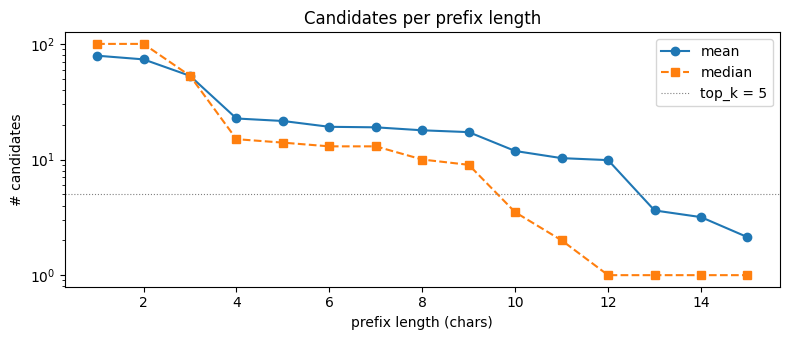

L= 1  mean=   79.1  median= 100.0
L= 2  mean=   73.5  median= 100.0
L= 3  mean=   52.9  median=  53.0
L= 4  mean=   22.6  median=  15.0
L= 5  mean=   21.5  median=  14.0
L= 6  mean=   19.2  median=  13.0
L= 7  mean=   19.0  median=  13.0
L= 8  mean=   17.9  median=  10.0
L= 9  mean=   17.3  median=   9.0
L=10  mean=   11.9  median=   3.5
L=11  mean=   10.3  median=   2.0
L=12  mean=    9.9  median=   1.0
L=13  mean=    3.6  median=   1.0
L=14  mean=    3.2  median=   1.0
L=15  mean=    2.1  median=   1.0


In [13]:
# Empirical look at the minimal prefix length:
# how many candidates does a prefix of length L return (before top-k cut)?
lengths = range(1, 16)
clean_titles = [clean_sentence(x) for x in dataset]
avg_cands, med_cands = [], []
for L in lengths:
    counts = [len(_prefix_lookup(t2, ct[:L])) for ct in clean_titles if len(ct) >= L]
    avg_cands.append(np.mean(counts))
    med_cands.append(np.median(counts))

plt.figure(figsize=(8, 3.5))
plt.plot(lengths, avg_cands, "o-", label="mean")
plt.plot(lengths, med_cands, "s--", label="median")
plt.axhline(5, color="grey", lw=0.8, ls=":", label="top_k = 5")
plt.yscale("log"); plt.xlabel("prefix length (chars)"); plt.ylabel("# candidates")
plt.title("Candidates per prefix length"); plt.legend(); plt.tight_layout(); plt.show()

for L, a, m in zip(lengths, avg_cands, med_cands):
    print(f"L={L:2d}  mean={a:7.1f}  median={m:6.1f}")

## 1.6 Matches in the middle of a title

What if the phrase the user types appears in the middle of a title?

**Idea:** index every **word suffix** of every normalized title. For `"deep residual networks image recognition"` we insert
`"deep residual networks image recognition"`, `"residual networks image recognition"`, `"networks image recognition"`, ...
A prefix search over these keys is then a search for the phrase starting at any word boundary. This is a word-level **suffix trie**, the same idea as a generalized suffix tree. It costs about as many keys as there are tokens in the collection.

In [14]:
t3 = pygtrie.CharTrie()
for idx, title in enumerate(dataset):
    tokens = clean_sentence(title).split()
    for k in range(len(tokens)):
        t3.setdefault(" ".join(tokens[k:]), []).append(idx)

print(f"t2: {len(t2)} keys,  t3 (word suffixes): {len(t3)} keys")

t2: 500 keys,  t3 (word suffixes): 3148 keys


In [15]:
## Tests
initials = ["3D Point Cloud", "Residual Network", "Supervised", "word length"]

for query in initials:
    print(query)
    clean = clean_sentence(query.lower(), stop_words)
    res = set(_prefix_lookup(t3, clean))
    for idx in sorted(res):
        print(f"\t {dataset[idx]}")
    print()

3D Point Cloud
	 3DCNN-DQN-RNN: A Deep Reinforcement Learning Framework for Semantic  Parsing of Large-scale 3D Point Clouds
	 Vote3Deep: Fast Object Detection in 3D Point Clouds Using Efficient  Convolutional Neural Networks

Residual Network
	 VoxResNet: Deep Voxelwise Residual Networks for Volumetric Brain  Segmentation
	 Wavelet Domain Residual Network (WavResNet) for Low-Dose X-ray CT  Reconstruction

Supervised
	 A Bayesian Model for Supervised Clustering with the Dirichlet Process  Prior
	 Progressive Representation Adaptation for Weakly Supervised Object  Localization
	 WESPE: Weakly Supervised Photo Enhancer for Digital Cameras

word length
	 Information content versus word length in natural language: A reply to  Ferrer-i-Cancho and Moscoso del Prado Martin [arXiv:1209.1751]
	 Information content versus word length in random typing



### Putting it together

A practical suggest shows **true prefix matches first** (the user is most likely typing the start of a title), then **fills the rest with matches in the middle**.

In [16]:
def suggest(query, top_k=5):
    head = complete_user_query(query, t2, top_k)
    if len(head) >= top_k:
        return head
    clean = clean_sentence(query)
    middle = set(_prefix_lookup(t3, clean)) - set(head)
    middle = sorted(middle, key=lambda i: (len(dataset[i]), i))
    return (head + middle)[:top_k]

for q in ["Residual Network", "supervised object", "Bayesian approach to"]:
    print("Query:", q)
    for idx in suggest(q):
        print(f"\t{idx}\t{dataset[idx]}")

Query: Residual Network
	435	VoxResNet: Deep Voxelwise Residual Networks for Volumetric Brain  Segmentation
	499	Wavelet Domain Residual Network (WavResNet) for Low-Dose X-ray CT  Reconstruction
Query: supervised object
	381	Progressive Representation Adaptation for Weakly Supervised Object  Localization
Query: Bayesian approach to
	47	A Bayesian Approach for Online Classifier Ensemble
	94	A Bayesian approach to type-specific conic fitting
	48	A Bayesian Approach to Constraint Based Causal Inference
	53	A Bayesian Approach to Tackling Hard Computational Problems
	50	A Bayesian Approach to Estimation of Speaker Normalization Parameters


---
# Part 2 — Audio search (Shazam)

Have you ever wondered what happens under the hood of the popular music-search app? How can a track be identified among millions of others from a few seconds of noisy audio? It's not brute force. We'll implement the algorithm ourselves.

Refer to the [original article (Wang, 2003)](https://www.ee.columbia.edu/~dpwe/papers/Wang03-shazam.pdf) for implementation details.

**Pipeline**

```
audio ─► spectrogram ─► peaks ("constellation") ─► peak pairs → hashes (f1, f2, Δt) ─► inverted index
                                                                                        │
clip  ─► same steps ─► hashes ─► look up in index ─► histogram of time offsets ─► peak = match + offset
```

## 2.1 Reading and resampling the audio database

The lab uses `ACDC.mp3`, `iamthemorning.mp3`, `Little Big.mp3` and the query `request.mp3` from `../datasets/mp3/`. **If those files are not found**, the next cell generates a small synthetic database (three random "melodies"), and makes the query a 15-second noisy excerpt that starts at 1:00 of the first track. The rest of the notebook runs the same either way.

In [17]:
SAMPLE_RATE = 22050         # resample everything to 22.05 kHz
HOP = 512                   # librosa's default hop length → time resolution of one spectrogram frame
TIME_RES = HOP / SAMPLE_RATE  # seconds per frame (~23 ms)

prefix = "../datasets/mp3/"
audios = ["ACDC.mp3", "iamthemorning.mp3", "Little Big.mp3"]
request_audio = "request.mp3"


def synth_track(seed, duration=150, sr=SAMPLE_RATE):
    # A random 'melody' of decaying harmonic notes plus a little noise
    rng = np.random.default_rng(seed)
    y = np.zeros(int(duration * sr), dtype=np.float32)
    pos = 0
    while True:
        dur = rng.choice([0.125, 0.25, 0.375, 0.5])
        n = int(dur * sr)
        if pos + n > len(y):
            break
        tt = np.arange(n) / sr
        for voice in range(rng.integers(1, 3)):              # 1-2 simultaneous notes
            f0 = 110 * 2 ** (rng.integers(0, 36) / 12)       # A2 .. A5
            note = sum(0.6 ** k * np.sin(2 * np.pi * f0 * (k + 1) * tt) for k in range(4))
            y[pos:pos + n] += (np.exp(-3 * tt / dur) * note).astype(np.float32)
        pos += n
    y += 0.01 * rng.standard_normal(len(y)).astype(np.float32)
    return 0.9 * y / np.abs(y).max()


def write_wav(path, y, sr=SAMPLE_RATE):
    wavfile.write(path, sr, (np.clip(y, -1, 1) * 32767).astype(np.int16))


if not all(os.path.exists(prefix + f) for f in audios + [request_audio]):
    print("Lab audio not found, so generating a synthetic database instead.")
    prefix = "./lab11_audio/"
    os.makedirs(prefix, exist_ok=True)
    audios = ["track_A.wav", "track_B.wav", "track_C.wav"]
    request_audio = "request.wav"
    tracks = [synth_track(seed) for seed in range(len(audios))]
    for name, y in zip(audios, tracks):
        write_wav(prefix + name, y)
    # The query: 15 s of track_A starting at 60 s, with noise added (SNR ≈ 10 dB)
    clip = tracks[0][60 * SAMPLE_RATE: 75 * SAMPLE_RATE].copy()
    noise = np.random.default_rng(42).standard_normal(len(clip)).astype(np.float32)
    clip += noise * np.sqrt(np.mean(clip ** 2) / 10 ** (10 / 10))
    write_wav(prefix + request_audio, 0.9 * clip / np.abs(clip).max())

reference_track = audios[0]   # the track that request_audio was cut from


def read_and_resample(path, sample_rate=SAMPLE_RATE):
    y, _ = librosa.load(path, sr=sample_rate)   # decode + resample + mono
    print(f"{path} length is {y.shape[0] / sample_rate / 60.:.2f} min")
    return y


dataset_audio = {name: read_and_resample(prefix + name) for name in audios}
request_data = read_and_resample(prefix + request_audio)

Lab audio not found, so generating a synthetic database instead.
./lab11_audio/track_A.wav length is 2.50 min
./lab11_audio/track_B.wav length is 2.50 min
./lab11_audio/track_C.wav length is 2.50 min
./lab11_audio/request.wav length is 0.25 min


## 2.2 Visualizing a spectrogram

We use the [Mel scale](https://en.wikipedia.org/wiki/Mel_scale), which spaces frequencies the way we hear them rather than linearly, and show power in decibels.

Spectrogram shape: (128, 6460)  (mel bins × frames),  23.2 ms per frame


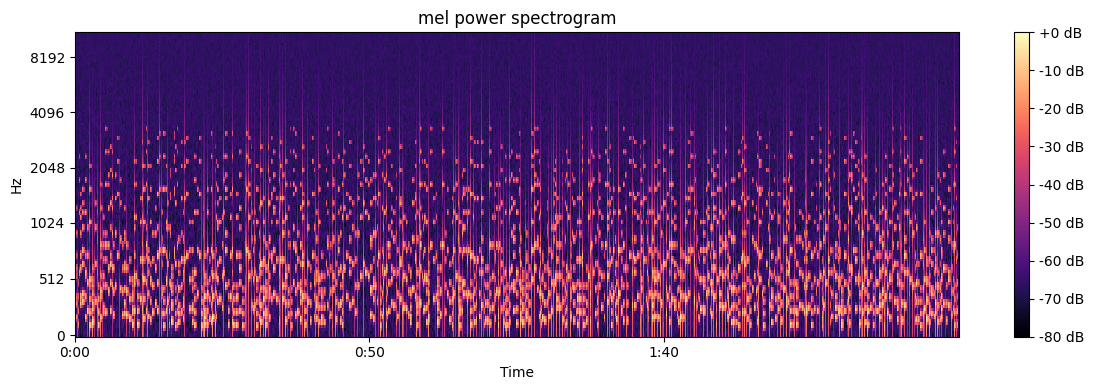

In [18]:
y = dataset_audio[reference_track]
S = librosa.feature.melspectrogram(y=y, sr=SAMPLE_RATE, n_mels=128, hop_length=HOP)
print(f"Spectrogram shape: {S.shape}  (mel bins × frames),  {TIME_RES * 1000:.1f} ms per frame")

log_S = librosa.power_to_db(S, ref=np.max)   # dB relative to the loudest bin

plt.figure(figsize=(12, 4))
librosa.display.specshow(log_S, sr=SAMPLE_RATE, hop_length=HOP, x_axis="time", y_axis="mel")
plt.title("mel power spectrogram")
plt.colorbar(format="%+02.0f dB")
plt.tight_layout(); plt.show()

## 2.3 Forming constellations

We turn the spectrogram into a sparse set of points, the way the paper does (our version differs in a few details):

<img src="https://cdn.dxomark.com/wp-content/uploads/medias/post-50538/Spectrogram_Fingerprinting.png" width="800"/>

1. Compute a mel spectrogram (256 bins up to 4 kHz, where most of the melodic energy is) in dB.
2. Find local maxima with a [computer-vision trick](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.maximum_filter.html): run a maximum filter, then compare the filtered image with the original. Where they are equal, the pixel is the maximum of its neighborhood.
3. In flat regions (for example silence clipped at −80 dB) every pixel "equals its neighborhood maximum". `ndimage.label()` groups those pixels into connected components. We keep only components of **size 1**, which are isolated peaks, or "stars".

Peaks are robust: noise, compression, and equalization change amplitudes, but the strongest time–frequency points usually stay where they are.

*Optimization compared with the original notebook:* we get component sizes in one call with `np.bincount` instead of looping over `find_objects`. Points come back as a `(N, 2)` array of `(t, f)`, sorted by time, which the index-building step needs.

track_A.wav            2340 stars
track_B.wav            2309 stars
track_C.wav            2284 stars
request.wav             318 stars


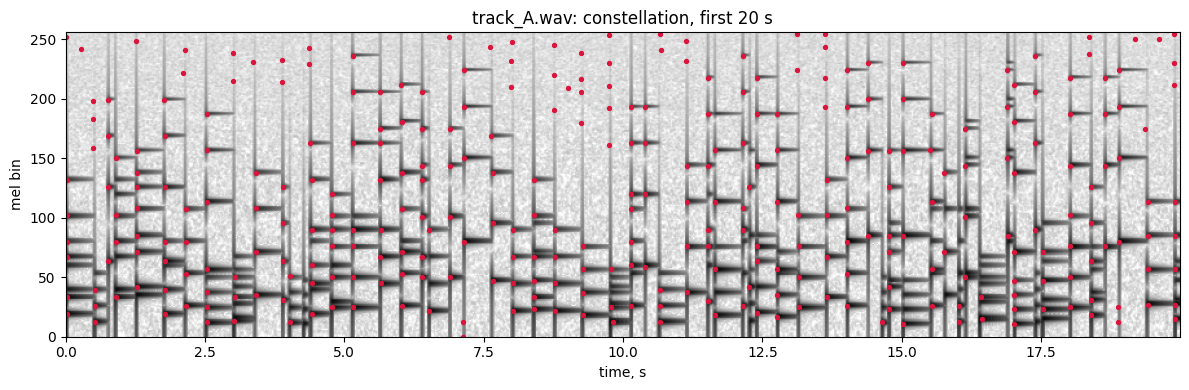

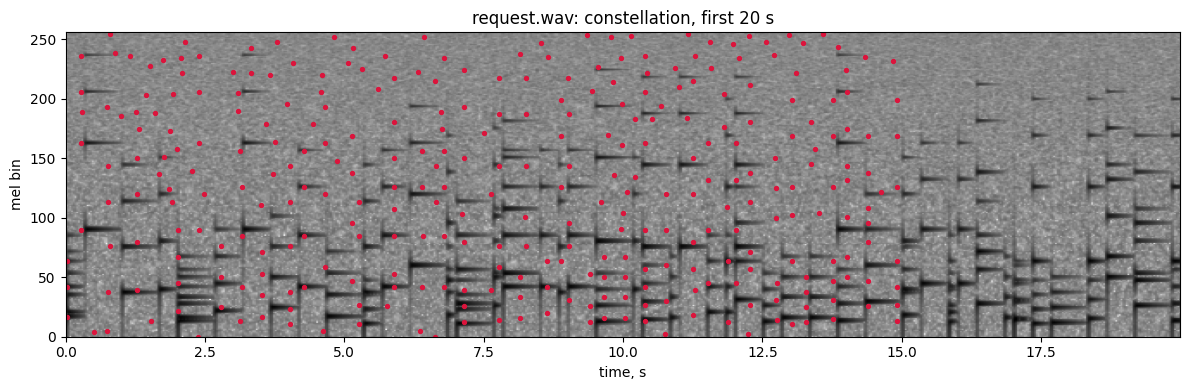

In [19]:
N_MELS, F_MAX = 256, 4000
NEIGHBORHOOD = 20         # size of the max-filter window (bins × frames)


def spectrogram_db(wav, sr=SAMPLE_RATE):
    S = librosa.feature.melspectrogram(y=wav, sr=sr, n_mels=N_MELS, fmax=F_MAX, hop_length=HOP)
    return librosa.power_to_db(S, ref=np.max)


def form_constellation(wav, sr=SAMPLE_RATE, neighborhood_size=NEIGHBORHOOD, min_db=None):
    S_db = spectrogram_db(wav, sr)
    is_peak = maximum_filter(S_db, size=neighborhood_size) == S_db
    if min_db is not None:                       # optional: ignore very quiet peaks
        is_peak &= S_db > min_db
    labels, _ = ndimage.label(is_peak)
    sizes = np.bincount(labels.ravel())
    single = is_peak & (sizes[labels] == 1)      # isolated peaks only
    f_idx, t_idx = np.nonzero(single)
    order = np.lexsort((f_idx, t_idx))           # sort by time, then frequency
    return np.column_stack([t_idx[order], f_idx[order]])


def plot_constellation(name, wav, seconds=20):
    S_db = spectrogram_db(wav)
    pts = form_constellation(wav)
    hi = int(seconds / TIME_RES)
    pts = pts[pts[:, 0] < hi]
    plt.figure(figsize=(12, 4))
    plt.imshow(S_db[:, :hi], origin="lower", aspect="auto", cmap="gray_r",
               extent=[0, hi * TIME_RES, 0, N_MELS])
    plt.scatter(pts[:, 0] * TIME_RES, pts[:, 1], s=8, c="crimson")
    plt.title(f"{name}: constellation, first {seconds} s"); plt.xlabel("time, s"); plt.ylabel("mel bin")
    plt.tight_layout(); plt.show()


constellations = {name: form_constellation(wav) for name, wav in dataset_audio.items()}
request_constellation = form_constellation(request_data)

for name, pts in list(constellations.items()) + [(request_audio, request_constellation)]:
    print(f"{name:20s} {len(pts):6d} stars")

plot_constellation(reference_track, dataset_audio[reference_track])
plot_constellation(request_audio, request_data)

## 2.4 Building the index from constellations

One star alone is not distinctive: a frequency bin carries almost no information. A **pair** of stars is. For every *anchor* star $(t_1, f_1)$:

1. Look at a **target zone** of time and frequency shifts after it. Here that is $\Delta t \in [1, 5]$ s and $\Delta f \in [-50, +50]$ **mel bins**. (The original notebook said "Hz", but the frequency axis is in mel bins.)
2. Pair the anchor with stars $(t_2, f_2)$ inside the zone. The paper pairs each anchor with only *some* of them. We use a **fan-out** limit and keep the first `FAN_OUT` targets in time, which keeps the index small and fast.
3. The key is $(f_1, f_2, \Delta t = t_2 - t_1)$ and the value is $(t_1, \text{filename})$. Because the key uses only *relative* time, the same hash comes out wherever the clip starts in the track.

*Optimization:* stars are sorted by time, so `np.searchsorted` finds each anchor's time window in $O(\log N)$ instead of scanning every pair, $O(N^2)$.

In [20]:
# (dt_min, dt_max) in frames, (df_min, df_max) in mel bins
target = (int(1 / TIME_RES), int(5 / TIME_RES), -50, 50)
FAN_OUT = 10


def build_constellation_index(constellation_collection, target=target, fan_out=FAN_OUT):
    dt_min, dt_max, df_min, df_max = target
    index = defaultdict(list)
    for name, points in constellation_collection.items():
        t, f = points[:, 0], points[:, 1]
        lo = np.searchsorted(t, t + dt_min, side="left")
        hi = np.searchsorted(t, t + dt_max, side="right")
        for i in range(len(points)):
            cand = np.arange(lo[i], hi[i])
            df = f[cand] - f[i]
            cand = cand[(df >= df_min) & (df <= df_max)][:fan_out]
            for j in cand:
                index[(int(f[i]), int(f[j]), int(t[j] - t[i]))].append((int(t[i]), name))
    return dict(index)


index = build_constellation_index(constellations)
request = build_constellation_index({request_audio: request_constellation})

n_entries = sum(len(v) for v in index.values())
print(f"database: {len(index):,} distinct keys, {n_entries:,} entries")
print(f"request : {len(request):,} distinct keys")

database: 43,574 distinct keys, 68,206 entries
request : 2,755 distinct keys


## 2.5 Comparing `request` with the database

1. Find every database key that also appears in the query.
2. For each match, compute the **time offset** $t_1^{\text{track}} - t_1^{\text{query}}$.
3. Count matches per offset with a histogram.

Random collisions spread offsets evenly. A true match makes many hashes agree on **one** offset, which shows up as a sharp spike: the clip starts at that point in the track.

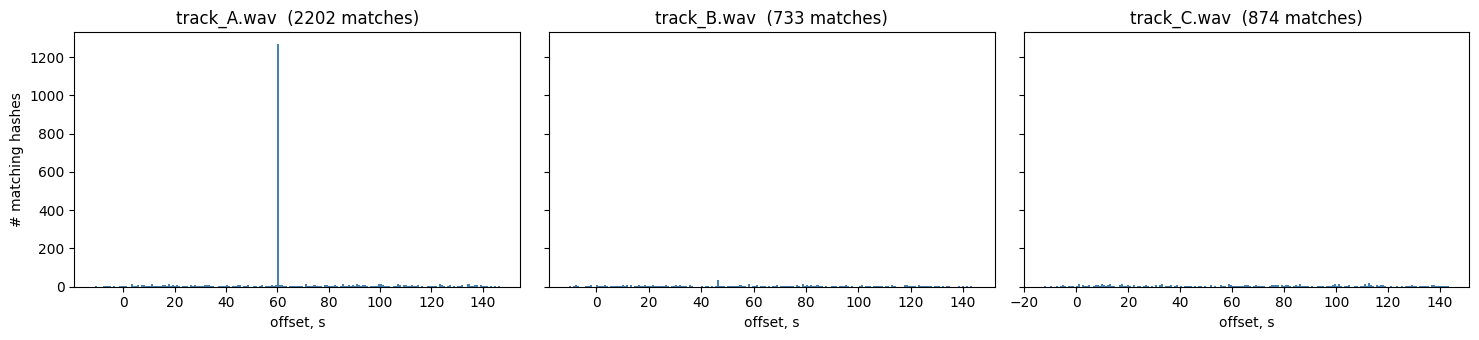

In [21]:
def match_offsets(db_index, query_index):
    # name → array of (t_db - t_query) for every matching hash pair
    offsets = defaultdict(list)
    for key, q_entries in query_index.items():
        db_entries = db_index.get(key)
        if not db_entries:
            continue
        for t_db, name in db_entries:
            offsets[name].extend(t_db - t_q for t_q, _ in q_entries)
    return {name: np.asarray(v) for name, v in offsets.items()}


offsets = match_offsets(index, request)

fig, axes = plt.subplots(1, len(audios), figsize=(15, 3.5), sharey=True)
for ax, name in zip(axes, audios):
    off = offsets.get(name, np.array([]))
    ax.hist(off * TIME_RES, bins=200, color="steelblue")
    ax.set_title(f"{name}  ({len(off)} matches)"); ax.set_xlabel("offset, s")
axes[0].set_ylabel("# matching hashes")
plt.tight_layout(); plt.show()

## 2.6 Similarity function

The function scores how similar two tracks are and returns **two numbers: a similarity score and the audio offset** (how far the start of the query is shifted relative to the track).

Design:
1. **Mode with tolerance.** Count offsets in 1-frame bins, then sum each bin with its neighbors (±`tol` frames) to absorb rounding jitter. The highest bin is the **mode**, which gives our offset.
2. **Normalize.** Similarity = (hashes that agree on the mode) / (hashes in the query). The score is in $[0, 1]$ and doesn't depend on clip length: about 1 for an identical clip, 0 for unrelated audio.
3. **Check the peak.** We also report the excess **kurtosis** of the offset distribution and the ratio of the peak to the background. A true match is very peaked (large kurtosis). Random collisions look roughly uniform (kurtosis ≤ 0). These help pick a decision threshold.

In [22]:
def fingerprint(audio):
    # Path or waveform → hash index of that single recording
    wav = read_and_resample(audio) if isinstance(audio, str) else audio
    return build_constellation_index({"x": form_constellation(wav)})


def offset_peak(off, tol=1):
    # Mode of the offset distribution, with ±tol frames tolerance
    shift = off.min()
    hist = np.bincount(off - shift)
    smoothed = np.convolve(hist, np.ones(2 * tol + 1, dtype=int), mode="same")
    best = int(np.argmax(smoothed))
    return best + shift, int(smoothed[best]), smoothed


def similarity(audio, query, tol=1, verbose=False):
    audio_idx = fingerprint(audio)
    query_idx = fingerprint(query)
    n_query = sum(len(v) for v in query_idx.values())

    off = match_offsets(audio_idx, query_idx).get("x")
    if off is None or len(off) == 0 or n_query == 0:
        return 0.0, None

    mode_frames, peak, smoothed = offset_peak(off, tol)
    sim = peak / n_query
    offset = mode_frames * TIME_RES
    if verbose:
        background = np.median(smoothed[smoothed > 0])
        print(f"query hashes={n_query}, matches={len(off)}, peak={peak}, "
              f"peak/background={peak / background:.1f}, kurtosis={kurtosis(off):.1f}")
    return sim, offset


sim, off = similarity(prefix + reference_track, prefix + request_audio, verbose=True)
print(f"similarity = {sim:.3f}, offset = {off:.2f} s")
assert abs(abs(off) - 60) < 5, "Offset value for these 2 tracks should be around 1 minute."

./lab11_audio/track_A.wav length is 2.50 min
./lab11_audio/request.wav length is 0.25 min
query hashes=2793, matches=2202, peak=1262, peak/background=631.0, kurtosis=1.2
similarity = 0.452, offset = 59.98 s


In [23]:
# The same score against the other tracks: they should come out near zero
for name in audios:
    s, o = similarity(dataset_audio[name], request_data)
    print(f"{name:20s} similarity={s:.3f}  offset={'—' if o is None else f'{o:6.2f} s'}")

track_A.wav          similarity=0.452  offset= 59.98 s
track_B.wav          similarity=0.005  offset= 46.63 s
track_C.wav          similarity=0.004  offset=112.48 s


## 2.7 Identifying a clip against the whole database

In a real system we don't compare the clip with one track at a time. We look it up **once** in the index we already built (§2.4), score every candidate track, and return the best one. The cost depends on how many hashes match, not on how big the database is.

In [24]:
def identify(query_wav, db_index=index, top=3, tol=1):
    q_idx = build_constellation_index({"q": form_constellation(query_wav)})
    n_query = sum(len(v) for v in q_idx.values())
    scores = []
    for name, off in match_offsets(db_index, q_idx).items():
        mode_frames, peak, _ = offset_peak(off, tol)
        scores.append((peak / n_query, name, mode_frames * TIME_RES))
    return sorted(scores, reverse=True)[:top]


for score, name, off in identify(request_data):
    print(f"{name:20s} score={score:.3f}  offset={off:6.2f} s")

track_A.wav          score=0.452  offset= 59.98 s
track_B.wav          score=0.005  offset= 46.63 s
track_C.wav          score=0.004  offset=112.48 s


### Robustness experiment

How much noise can the fingerprint take? We add white noise to the request at decreasing signal-to-noise ratios (SNR) and check whether it's still identified at the right offset.

In [25]:
rng = np.random.default_rng(0)
signal_power = np.mean(request_data ** 2)
print(f"{'SNR, dB':>8} | {'best match':20s} | {'score':>6} | {'offset, s':>9}")
for snr in [20, 10, 5, 0, -5]:
    noisy = request_data + rng.standard_normal(len(request_data)).astype(np.float32) \
            * np.sqrt(signal_power / 10 ** (snr / 10))
    score, name, off = identify(noisy, top=1)[0]
    print(f"{snr:8d} | {name:20s} | {score:6.3f} | {off:9.2f}")

 SNR, dB | best match           |  score | offset, s
      20 | track_A.wav          |  0.435 |     59.98
      10 | track_A.wav          |  0.409 |     59.98
       5 | track_A.wav          |  0.331 |     59.98
       0 | track_A.wav          |  0.306 |     59.98
      -5 | track_A.wav          |  0.238 |     59.98
